In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("salader/dogsvscats")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'dogsvscats' dataset.
Path to dataset files: /kaggle/input/dogsvscats


In [2]:
import os

for root, dirs, files in os.walk(path):
    print(root, "->", len(files), "files")

/kaggle/input/dogsvscats -> 0 files
/kaggle/input/dogsvscats/test -> 0 files
/kaggle/input/dogsvscats/test/dogs -> 2500 files
/kaggle/input/dogsvscats/test/cats -> 2500 files
/kaggle/input/dogsvscats/train -> 0 files
/kaggle/input/dogsvscats/train/dogs -> 10000 files
/kaggle/input/dogsvscats/train/cats -> 10000 files
/kaggle/input/dogsvscats/catsvsdogs -> 0 files
/kaggle/input/dogsvscats/catsvsdogs/test -> 0 files
/kaggle/input/dogsvscats/catsvsdogs/test/dogs -> 2500 files
/kaggle/input/dogsvscats/catsvsdogs/test/cats -> 2500 files
/kaggle/input/dogsvscats/catsvsdogs/train -> 0 files
/kaggle/input/dogsvscats/catsvsdogs/train/dogs -> 10000 files
/kaggle/input/dogsvscats/catsvsdogs/train/cats -> 10000 files


In [3]:
train_dir = os.path.join(path, "train")
test_dir = os.path.join(path, "test")

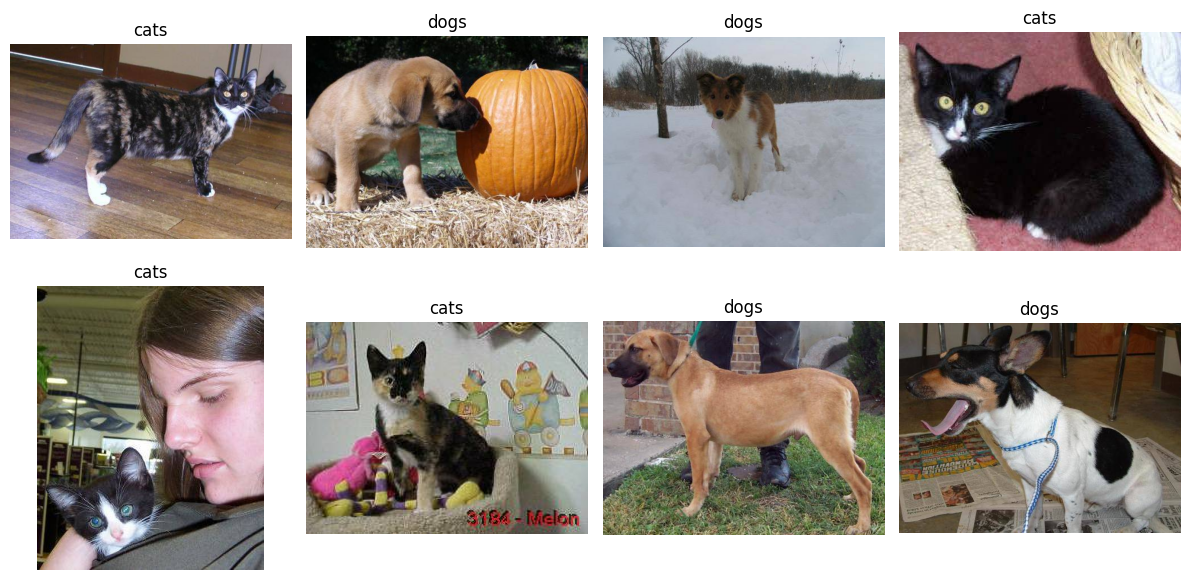

In [4]:
import os
import matplotlib.pyplot as plt
from PIL import Image
import random

train_dir = os.path.join(path, "train")

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax in axes.flat:
    category = random.choice(["cats", "dogs"])
    folder = os.path.join(train_dir, category)

    filename = random.choice(os.listdir(folder))
    img_path = os.path.join(folder, filename)

    img = Image.open(img_path).convert("RGB")

    ax.imshow(img)
    ax.set_title(category)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [16]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D, Flatten,BatchNormalization,Dropout


In [6]:
train_ds = keras.utils.image_dataset_from_directory(
    directory=train_dir,
    labels="inferred",
    label_mode="int",
    batch_size=32,
    image_size=(256, 256),
)

Found 20000 files belonging to 2 classes.


In [7]:
val_ds = keras.utils.image_dataset_from_directory(
    directory=test_dir,
    labels="inferred",
    label_mode="int",
    batch_size=32,
    image_size=(256, 256),
)

Found 5000 files belonging to 2 classes.


In [8]:
def process(image, label):
    image = tf.cast(image / 255.0, tf.float32)
    return image, label


train_ds = train_ds.map(process)
val_ds = val_ds.map(process)

In [21]:
model = Sequential()

model.add(Conv2D(32, kernel_size=(3, 3), padding="valid", activation="relu", input_shape=(256, 256,3)))
model.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding="valid"))

model.add(Conv2D(64, kernel_size=(3, 3), padding="valid", activation="relu"))
model.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding="valid"))

model.add(Conv2D(128, kernel_size=(3, 3), padding="valid", activation="relu"))
model.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding="valid"))

model.add(Flatten())

model.add(Dense(128, activation="relu"))
model.add(Dense(64, activation="relu"))
model.add(Dense(1, activation="sigmoid"))

In [22]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,847,297 (56.64 MB)

 Trainable params: 14,847,297 (56.64 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

In [24]:
h = model.fit(train_ds, epochs=10, validation_data=val_ds)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 64s 97ms/step - accuracy: 0.6410 - loss: 0.6299 - val_accuracy: 0.7356 - val_loss: 0.5368
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 58s 92ms/step - accuracy: 0.7701 - loss: 0.4807 - val_accuracy: 0.7904 - val_loss: 0.4600
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 57s 90ms/step - accuracy: 0.8297 - loss: 0.3736 - val_accuracy: 0.7908 - val_loss: 0.4650
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 55s 88ms/step - accuracy: 0.8974 - loss: 0.2414 - val_accuracy: 0.7864 - val_loss: 0.6654
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 54s 86ms/step - accuracy: 0.9516 - loss: 0.1227 - val_accuracy: 0.7932 - val_loss: 0.7901
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 53s 84ms/step - accuracy: 0.9691 - loss: 0.0861 - val_accuracy: 0.7862 - val_loss: 1.1039
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 53s 84ms/step - accuracy: 0.9815 - loss: 0.0524 - val_accuracy: 0.7802 - val_loss: 1.3662
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 53s 84ms/step - accuracy: 0.9866 - loss: 0.0456 - 

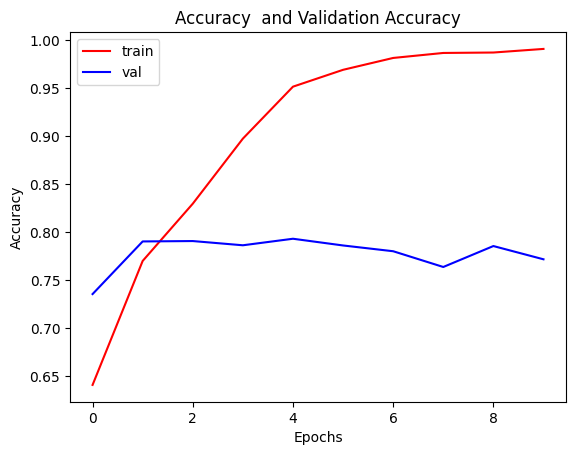

In [25]:

import matplotlib.pyplot as plt

plt.plot(h.history["accuracy"],color='red',label='train')
plt.plot(h.history["val_accuracy"],color='blue',label='val')
plt.legend()
plt.title("Accuracy  and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.show()

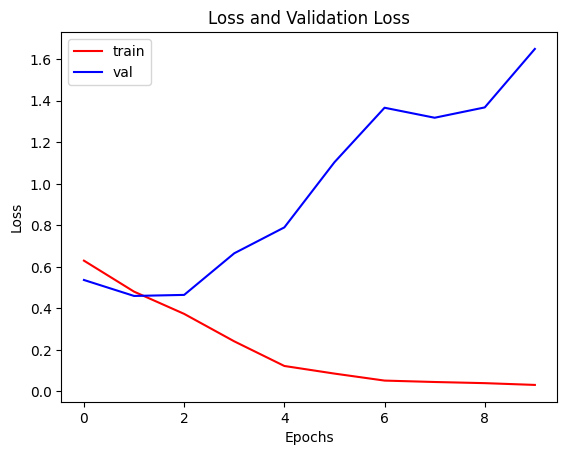

In [26]:
plt.plot(h.history["loss"],color='red',label='train')
plt.plot(h.history["val_loss"],color='blue',label='val')
plt.legend()
plt.title("Loss and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()

In [28]:
model1 = Sequential()

model1.add(Conv2D(32, kernel_size=(3, 3), padding="valid", activation="relu", input_shape=(256, 256,3)))
model1.add(BatchNormalization())
model1.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding="valid"))

model1.add(Conv2D(64, kernel_size=(3, 3), padding="valid", activation="relu"))
model1.add(BatchNormalization())
model1.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding="valid"))

model1.add(Conv2D(128, kernel_size=(3, 3), padding="valid", activation="relu"))
model1.add(BatchNormalization())
model1.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding="valid"))

model1.add(Flatten())

model1.add(Dense(128, activation="relu"))
model1.add(Dropout(0.1))
model1.add(Dense(64, activation="relu"))
model1.add(Dropout(0.1))
model1.add(Dense(1, activation="sigmoid"))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [27]:
model1.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,541,893 (169.91 MB)

 Trainable params: 14,847,297 (56.64 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 29,694,596 (113.28 MB)

In [29]:
model1.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

In [30]:
h1 = model1.fit(train_ds, epochs=10, validation_data=val_ds)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 69s 101ms/step - accuracy: 0.5957 - loss: 1.3611 - val_accuracy: 0.6986 - val_loss: 0.5873
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 61s 98ms/step - accuracy: 0.7006 - loss: 0.5718 - val_accuracy: 0.7016 - val_loss: 0.5676
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 61s 97ms/step - accuracy: 0.7533 - loss: 0.5069 - val_accuracy: 0.7116 - val_loss: 0.5562
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 61s 98ms/step - accuracy: 0.7987 - loss: 0.4351 - val_accuracy: 0.7378 - val_loss: 0.5167
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 61s 97ms/step - accuracy: 0.8331 - loss: 0.3763 - val_accuracy: 0.7696 - val_loss: 0.5032
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 63s 101ms/step - accuracy: 0.8730 - loss: 0.2988 - val_accuracy: 0.7898 - val_loss: 0.5549
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 64s 102ms/step - accuracy: 0.9100 - loss: 0.2219 - val_accuracy: 0.7694 - val_loss: 0.6408
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 64s 102ms/step - accuracy: 0.9431 - loss: 0.144

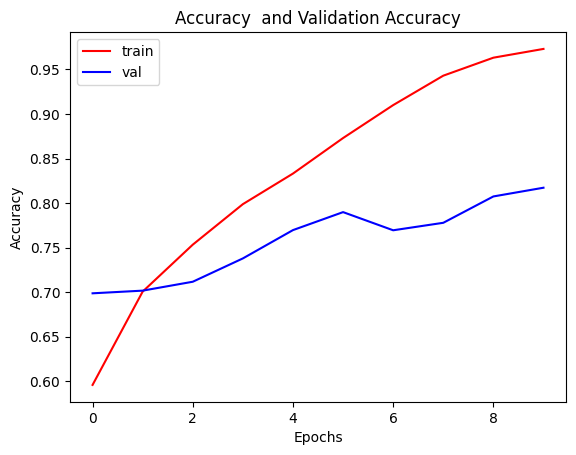

In [31]:
import matplotlib.pyplot as plt

plt.plot(h1.history["accuracy"],color='red',label='train')
plt.plot(h1.history["val_accuracy"],color='blue',label='val')
plt.legend()
plt.title("Accuracy  and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.show()

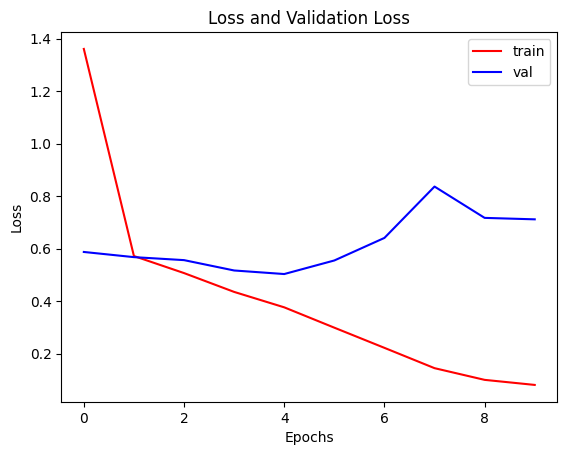

In [32]:
plt.plot(h1.history["loss"],color='red',label='train')
plt.plot(h1.history["val_loss"],color='blue',label='val')
plt.legend()
plt.title("Loss and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()

In [40]:
import cv2

In [45]:
test_img = cv2.imread('/content/cat image.jpg')

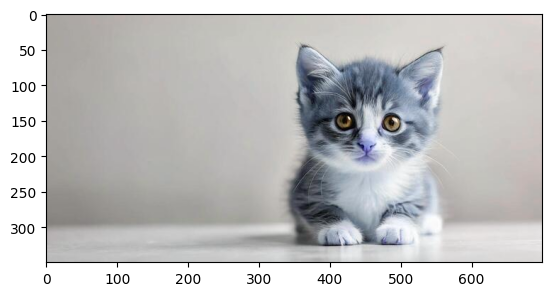

In [46]:
plt.imshow(test_img)

In [47]:
test_img.shape

(350, 700, 3)

In [48]:
test_img = cv2.resize(test_img,(256,256))

In [49]:
test_input = test_img.reshape((1,256,256,3))

In [50]:
model.predict(test_input)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


array([[0.]], dtype=float32)